清理前: 187963 筆 | 清理後: 187962 筆 | 移除: 1 筆


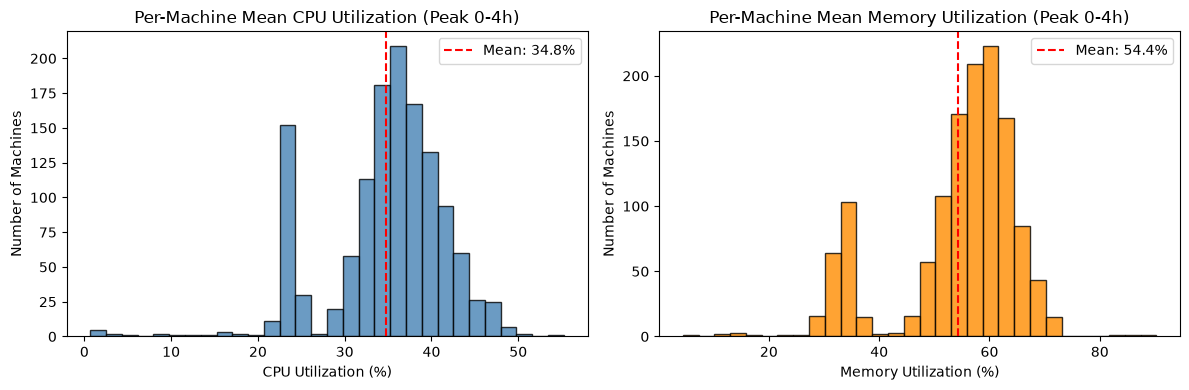

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. 讀取資料（路徑直接對應根目錄下的 data/）
col_names = [
    'timestamp',
    'machine_id',
    'util_cpu',
    'util_mem',
    'util_disk',
    'load1',
    'load5',
    'load15',
]
df = pd.read_csv(
    'data/server_usage.csv',
    names=col_names,
    usecols=['timestamp', 'machine_id', 'util_cpu', 'util_mem', 'load1'],
)

# 2. 資料清理
raw_count = len(df)
df = df.dropna(subset=['util_cpu', 'util_mem'])
df = df[
    (df['util_cpu'] >= 0)
    & (df['util_cpu'] <= 100)
    & (df['util_mem'] >= 0)
    & (df['util_mem'] <= 100)
]
print(
    f'清理前: {raw_count} 筆 | 清理後: {len(df)} 筆 | 移除:'
    f' {raw_count - len(df)} 筆'
)

# 3. 轉換相對小時（trace 從 39600 秒開始，減掉 39600 才會從 0 小時起算）
df['hour'] = ((df['timestamp'] - 39600) // 3600).astype(int)

# 4. 篩選第一週已鎖定的尖峰時段（Hours 0–4，即 hour 0, 1, 2, 3）
df_peak = df[(df['hour'] >= 0) & (df['hour'] < 4)]
df_peak.to_csv('data/peak_usage.csv', index=False)

# --- 圖表 1：尖峰時段內各機器的平均 CPU 與 Memory 使用率分佈 ---
machine_stats = (
    df_peak.groupby('machine_id')[['util_cpu', 'util_mem']].mean().reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# CPU 分佈
axes[0].hist(
    machine_stats['util_cpu'],
    bins=30,
    color='steelblue',
    edgecolor='black',
    alpha=0.8,
)
axes[0].axvline(
    machine_stats['util_cpu'].mean(),
    color='red',
    linestyle='--',
    label=f"Mean: {machine_stats['util_cpu'].mean():.1f}%",
)
axes[0].set_title('Per-Machine Mean CPU Utilization (Peak 0-4h)')
axes[0].set_xlabel('CPU Utilization (%)')
axes[0].set_ylabel('Number of Machines')
axes[0].legend()

# Memory 分佈
axes[1].hist(
    machine_stats['util_mem'],
    bins=30,
    color='darkorange',
    edgecolor='black',
    alpha=0.8,
)
axes[1].axvline(
    machine_stats['util_mem'].mean(),
    color='red',
    linestyle='--',
    label=f"Mean: {machine_stats['util_mem'].mean():.1f}%",
)
axes[1].set_title('Per-Machine Mean Memory Utilization (Peak 0-4h)')
axes[1].set_xlabel('Memory Utilization (%)')
axes[1].set_ylabel('Number of Machines')
axes[1].legend()

plt.tight_layout()
plt.savefig('week2_peak_resource_dist.png', dpi=300)
plt.show()